# Stage 07 — Published expansion portfolio and delayed teaching schedule

Use the owner-selected `AJUSTE-PME-2026.pdf`, whose actual title is **Anexos ajuste PME 2023–2032**. Preserve all 50 generation and 73 grid-work records with their page/annex citations. The restored chapters 3–5 are older source evidence; they are not relabeled as the latest adjustment.

The seven-year delay is an explicit teaching assumption applied to every published date, including half-year labels. The unchanged 2022 baseline remains provisionally calibrated, FAIL/PARTIAL. This notebook prepares data and diagnostics; it does not assemble or solve a future network.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.environment import check_environment, format_environment_report
from src.artifacts import run_preflight
environment = check_environment()
if not environment.ok:
    raise RuntimeError(format_environment_report(environment))
preflight = run_preflight("07_planning", root=ROOT)
preflight.raise_for_errors()
print(format_environment_report(environment))
print(f"Stage 07 integrity: PASS ({len(preflight.required_ids)} required inputs)")

Environment preflight: PASS
  environment: pypsa-earth-ec (expected pypsa-earth-ec)
  python: 3.11.14 (required >=3.10,<3.12)
  pypsa: 0.30.3 (>=0.25,<=0.30.3) [ok]
  numpy: 1.26.4 (<2) [ok]
  pandas: 2.3.3 (>=2) [ok]
  xarray: 2025.1.2 (>=2023.11.0,<=2025.1.2) [ok]
  h5netcdf: 1.7.3 (>=1) [ok]
  PyYAML: 6.0.3 (>=6) [ok]
  requests: 2.32.5 (>=2) [ok]
  jsonschema: 4.25.1 (>=4) [ok]
  nbformat: 5.10.4 (>=5) [ok]
  nbclient: 0.10.2 (>=0.10) [ok]
Stage 07 integrity: PASS (17 required inputs)


## Sources, units and outputs

| Input | Role | Units / locator |
|---|---|---|
| Adjustment PDF and two source transcriptions | Published schedule: Annex A generation; B/C grid works | MW, GWh/year, kV, km, MVA where reported; PDF pages 1–4 |
| Printed-total transcription | Preserve source totals separately from row sums | PDF page 2; no repair of printed values |
| Legacy generation/grid extracts | Preserved evidence and same-name coordinate candidates | Unverified legacy coordinates, not official sites |
| 2022 location evidence and fleet | Province+canton proxy points and baseline-name checks | WGS84 longitude/latitude in degrees |
| `config/planning.yaml` | Default delay, target year, repeat exercise and coordinate methods | Years; all assumptions remain separate |

Outputs: `data/processed/planning/projects.csv` contains **every** source row. The four direct asset interfaces (`generation.csv`, `lines.csv`, `transformers.csv`, `substations.csv`) contain a subset; compound systems, reactive/mobile equipment, storage and modernization remain in the full inventory. `exercise_schedule.csv` contains assumptions and readiness status. `portfolio_manifest.json` pins all inputs and outputs. Original manual evidence and nuclear records remain under `data/interim/planning/`.

Null normalized quantities mean either genuinely absent quantities or explicitly `not_normalized` equipment expressions. No circuit, rating, retirement or electrical connection is invented.

In [2]:
import pandas as pd
from scripts.migrate_phase07_planning import migrate
from src.planning_products import build_products, load_config, query_inventory
from src.planning import validate_published_portfolio, select_exercise_by_year, PlanningValidationError

config = load_config(ROOT)
# Student controls: change these notebook parameters; core Python stays unchanged.
DELAY_YEARS = config["exercise"]["delay_years"]
TARGET_YEAR = config["exercise"]["target_year"]

migrate(ROOT)
projects, tables, exercise, metadata = build_products(ROOT, delay_years=DELAY_YEARS)
assert validate_published_portfolio(tables).empty
assert len(projects) == 123 and projects.project_id.is_unique
assert (exercise.exercise_year - exercise.published_year == DELAY_YEARS).all()
OUTPUT = ROOT / "results/phase_07"
FIGURES = ROOT / "reports/figures/phase_07"
FIGURES.mkdir(parents=True, exist_ok=True)
display(projects.groupby("asset_type").size().rename("published_records").reset_index())
print("Published evidence: PASS. This does not assert physical model readiness.")

,asset_type,published_records
0,compound_grid_system,28
1,generator,50
2,line,9
3,mobile_equipment,4
4,plant_modernization,1
5,reactive,12
6,storage,1
7,substation,16
8,transformer,2


Published evidence: PASS. This does not assert physical model readiness.


## Query the full portfolio by year

`query_inventory` includes every source category, without silently dropping composite projects. A zero delay asks what the source scheduled through year Y; an explicit seven-year delay asks what the teaching exercise schedules through Y. The original commissioning year and raw half-year text remain unchanged.

The exercise is a repeat, not a statement that all projects remain unbuilt. Sarapullo and Minas de Huascachaca match the 2022 fleet. Known baseline matches retain their plant IDs; unmatched names remain **unknown**, not established as absent. Repeated exercise IDs are prefixed `EX_REPEAT_`.

In [3]:
published = query_inventory(projects, TARGET_YEAR, delay_years=0)
delayed = query_inventory(projects, TARGET_YEAR, delay_years=DELAY_YEARS)
print(f"Through {TARGET_YEAR}: {len(published)} published records; {len(delayed)} delayed exercise records")
display(exercise[["project_id", "official_name", "published_timing", "exercise_timing", "coordinate_method", "baseline_asset_id", "model_blockers"]].head(12))
display(pd.read_csv(ROOT / "data/processed/planning/project_relationships.csv"))

Through 2039: 123 published records; 123 delayed exercise records


,project_id,official_name,published_timing,exercise_timing,coordinate_method,baseline_asset_id,model_blockers
0,PME26_A_001,Sarapullo,2023,2030,same_name_legacy,ec2022_033_Sarapullo,electrical_connection_not_defined
1,PME26_A_002,Minas de Huascachaca,2023,2030,unique_canton,ec2022_030_Huascachaca,electrical_connection_not_defined
2,PME26_A_003,Huayquichuma,2023,2030,same_name_legacy,None,electrical_connection_not_defined
3,PME26_A_004,Bloque 1 de generación firme - 400 MW,2024,2031,same_name_legacy,None,electrical_connection_not_defined
4,PME26_A_005,Alluriquín,2024,2031,same_name_legacy,None,electrical_connection_not_defined
5,PME26_A_006,El Aromo,2025,2032,same_name_legacy,None,electrical_connection_not_defined
6,PME26_A_007,Villonaco III,2025,2032,same_name_legacy,None,electrical_connection_not_defined
7,PME26_A_008,Bloque 2 de generación firme - 300 MW,2025,2032,same_name_legacy,None,electrical_connection_not_defined
8,PME26_A_009,Machala Gas Tercera Unidad,2026,2033,same_name_legacy,None,electrical_connection_not_defined
9,PME26_A_010,Mazar-Dudas: San Antonio,2026,2033,same_name_legacy,None,electrical_connection_not_defined


,project_id,related_project_id,relationship,resolution,reason
0,PME26_B_039,PME26_B_045,potential_overlap,unresolved,Ibarra-Pimampiro descriptions share corridor/y...
1,PME26_B_052,PME26_B_055,potential_overlap,unresolved,Shushufindi-Orellana descriptions may overlap;...
2,PME26_B_026,PME26_B_031,potential_overlap,unresolved,Portoviejo works report different bank capacit...


## Source totals and overlap

The 50 capacity rows sum to 8,818.75 MW, matching the printed combined capacity total. Their annual mean-energy values sum to 48,759.01 GWh/year, whereas the printed combined total is 47,413 GWh/year. Preserve the **1,346.01 GWh/year** discrepancy; do not calibrate dispatch to either value here. Some printed subtotal typography is also unusual and is retained verbatim.

Ibarra–Pimampiro, Shushufindi–Orellana and Portoviejo entries have possible overlap or replacement relationships. They remain separate cited source records, with an unresolved relationship register; do not add their equipment quantities as distinct physical additions without review.

A separate source consistency check flags Tugaduaja 2 – Fase 2: its listed 2,058 GWh/year exceeds 150 MW × 8,760 h = 1,314 GWh. Preserve the published numbers and flag the issue; these annual-energy fields are not dispatch targets.

,comparison,row_sum,printed_total,unit,difference
0,generation_capacity,8818.75,8818.75,MW,0.00
1,generation_mean_energy,48759.01,47413.00,GWh/year,1346.01


,project_id,official_name,normalized_value,energy_gwh_year,nameplate_8760h_gwh,implied_capacity_factor,energy_above_nameplate_8760h
48,PME26_A_049,Tugaduaja 2 – Fase 2,150.0,2058.0,1314.0,1.56621,True


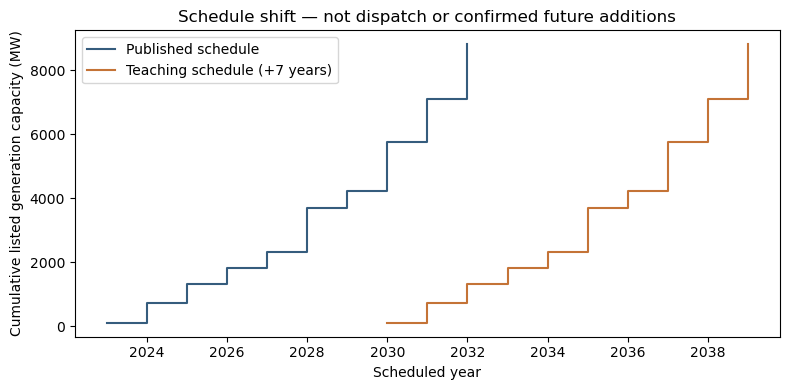

In [4]:
reconciliation = pd.read_csv(OUTPUT / "source_total_reconciliation.csv")
display(reconciliation)
source_checks = pd.read_csv(OUTPUT / "generation_source_checks.csv")
display(source_checks.loc[source_checks.energy_above_nameplate_8760h])
import matplotlib.pyplot as plt
gen = tables["generation"].groupby("commissioning_year").normalized_value.sum().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.step(gen.index, gen.cumsum(), where="post", label="Published schedule", color="#355c7d")
ax.step(gen.index + DELAY_YEARS, gen.cumsum(), where="post", label=f"Teaching schedule (+{DELAY_YEARS} years)", color="#c47336")
ax.set(xlabel="Scheduled year", ylabel="Cumulative listed generation capacity (MW)", title="Schedule shift — not dispatch or confirmed future additions")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "published_vs_delayed_generation.png", dpi=200)
plt.show()

## Coordinate assumptions and physical readiness

Same-name legacy matches are accepted only when they give a unique coordinate. Canton proxies require matching province and canton and a unique retained point. All such points have low confidence and remain modeling assumptions. Source placeholders such as “Por definir,” ambiguous names and conflicting points stay unresolved. No province centroid or nearest-bus electrical connection is silently substituted.

The amendment is a schedule summary, not a complete equipment model. Explicit unknown connections, voltage nodes, impedances, ratings and composite-project decomposition prevent strict model-ready selection. These prerequisites remain part of Phase 07 acceptance; successful extraction must not be called a runnable expansion.

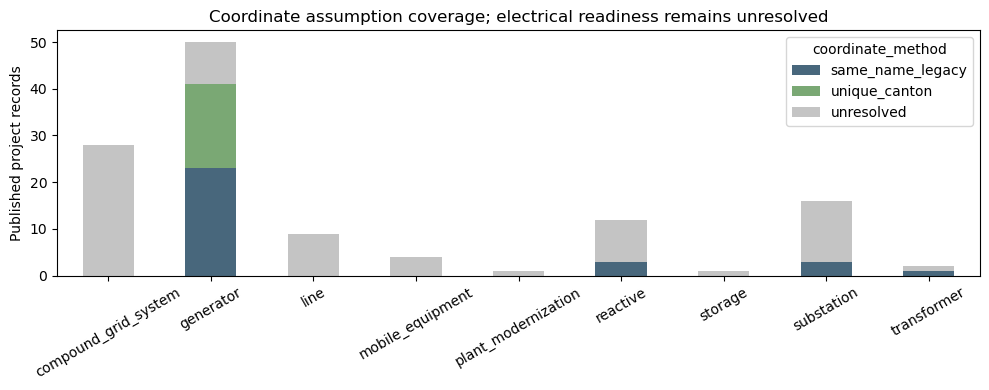

MODEL-READY PORTFOLIO: BLOCKED — missing physical definitions are reported below.


,project_id,severity,code,detail
0,PME26_A_001,error,coordinates,"latitude must be finite and within [-90, 90]"
1,PME26_A_001,error,coordinates,"longitude must be finite and within [-180, 180]"
2,PME26_A_001,error,missing_connection,Generator substation_id must identify a substa...
3,PME26_A_002,error,coordinates,"latitude must be finite and within [-90, 90]"
4,PME26_A_002,error,coordinates,"longitude must be finite and within [-180, 180]"
5,PME26_A_002,error,missing_connection,Generator substation_id must identify a substa...
6,PME26_A_003,error,coordinates,"latitude must be finite and within [-90, 90]"
7,PME26_A_003,error,coordinates,"longitude must be finite and within [-180, 180]"
8,PME26_A_003,error,missing_connection,Generator substation_id must identify a substa...
9,PME26_A_004,error,coordinates,"latitude must be finite and within [-90, 90]"


In [5]:
coverage = exercise.groupby(["asset_type", "coordinate_method"]).size().unstack(fill_value=0)
coverage.to_csv(OUTPUT / "coordinate_coverage.csv")
ax = coverage.plot.bar(stacked=True, figsize=(10, 4), rot=30, color=["#48677c", "#7aa874", "#c4c4c4"])
ax.set(ylabel="Published project records", xlabel="", title="Coordinate assumption coverage; electrical readiness remains unresolved")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES / "coordinate_coverage.png", dpi=200)
plt.show()
try:
    select_exercise_by_year(tables, TARGET_YEAR, delay_years=DELAY_YEARS, repeat_mode=config["exercise"]["repeat_mode"])
except PlanningValidationError as error:
    print("MODEL-READY PORTFOLIO: BLOCKED — missing physical definitions are reported below.")
    display(error.issues.head(15))
else:
    print("Model-ready selection passed.")

## Handoff

The source inventory, queries, delayed schedule, retained manual evidence, assumptions and diagnostics are reproducible. Full Phase 07 model-ready acceptance is still blocked until physical connections and parameters are defined, source overlaps are resolved and every selected project has complete dependencies. No 2022 network or validation gate changed. See `docs/PLANNING_DATA.md` and `reports/PHASE_07_TECHNICAL_REPORT.md` for exact commands, source hashes and the unresolved readiness checklist.

The owner approved deferring the missing physical values as later teaching assumptions. This completes the source-data and schedule handoff within that agreed scope; it does not pass the original fully model-ready portfolio gate.